# Week 10 Lab Work

**Dataset:** Adult / Census Income (UCI Machine Learning Repository)

1. Load the same pre-processed dataset as the last lab works.
2. Split it into training (70%), testing (15%), and validation (15%).
3. Check the data quickly (missing values, duplicates, class counts).
4. Scale the features and choose k (elbow and silhouette).
5. Apply the k-means algorithm with k = 2 and score it on the test set.
6. Draw the clusters in 2D with PCA.
7. Profile the clusters.
8. Compare the results with the previous results (Week 07 Decision Trees, Week 09 SVM and KNN).
9. Discussion and conclusions.

## 1. Load the data

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             silhouette_score, adjusted_rand_score, normalized_mutual_info_score,
                             classification_report, ConfusionMatrixDisplay)

cols = ["age", "workclass", "fnlwgt", "education", "education-num",
        "marital-status", "occupation", "relationship", "race", "sex",
        "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]


def get_file(data_filename):
    for base in [".", ".."]:
        if not os.path.isdir(base):
            continue
        for root, dirs, files in os.walk(base):
            if data_filename in files:
                return os.path.join(root, data_filename)

    print(f"'{data_filename}' not found in the workspace. Downloading it dynamically...")
    url = f"https://archive.ics.uci.edu/ml/machine-learning-databases/adult/{data_filename}"
    urllib.request.urlretrieve(url, data_filename)
    return data_filename


# 1. Load and pre-process the data
path = get_file("adult.data")
print(f"Loading data from: {path}")
df = pd.read_csv(path, header=None, names=cols, skipinitialspace=True, na_values="?")
df = df.dropna().drop_duplicates().reset_index(drop=True)
df["income"] = (df["income"] == ">50K").astype(int)
df = pd.get_dummies(df, drop_first=True)

print("Shape:", df.shape)
print("Missing cells:", df.isnull().sum().sum())
df.head()

Loading data from: ./adult.data
Shape: (30139, 97)
Missing cells: 0


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,77516,13,2174,0,40,0,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50,83311,13,0,0,13,0,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,38,215646,9,0,0,40,0,False,True,False,...,False,False,False,False,False,False,False,True,False,False
3,53,234721,7,0,0,40,0,False,True,False,...,False,False,False,False,False,False,False,True,False,False
4,28,338409,13,0,0,40,0,False,True,False,...,False,False,False,False,False,False,False,False,False,False


## 2. Train, test and validation split

In [2]:
X = df.drop(columns=["income"])
y = df["income"]

# 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# split the remaining 30% into 15% test / 15% validation
X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print(f"Train set: {len(X_train)} rows ({len(X_train)/len(df):.1%})")
print(f"Test set:  {len(X_test)} rows ({len(X_test)/len(df):.1%})")
print(f"Val set:   {len(X_val)} rows ({len(X_val)/len(df):.1%})")

Train set: 21097 rows (70.0%)
Test set:  4521 rows (15.0%)
Val set:   4521 rows (15.0%)


## 3. Quick check

In [3]:
raw = pd.read_csv(get_file("adult.data"), header=None, names=cols, skipinitialspace=True, na_values="?")
print("Raw rows:", len(raw))
print("Rows with missing values ('?'):", raw.isnull().any(axis=1).sum())
print("Duplicate rows:", raw.dropna().duplicated().sum())
print("Rows kept after cleaning:", len(df))
print()
counts = df["income"].value_counts().rename({0: "0 (<=50K)", 1: "1 (>50K)"})
print(counts)
print((counts / len(df)).round(4).rename("share"))

Raw rows: 32561
Rows with missing values ('?'): 2399
Duplicate rows: 23
Rows kept after cleaning: 30139

income
0 (<=50K)    22633
1 (>50K)      7506
Name: count, dtype: int64
income
0 (<=50K)    0.751
1 (>50K)     0.249
Name: share, dtype: float64


## 4. Scaling and choosing k

K-means uses distances, so the features are scaled with `StandardScaler` (fitted on the training set only). The `income` column is **not** a feature. K-means never sees it.

### 4.1 Elbow method and silhouette score

The silhouette score uses `sample_size=5000` because the full score on all training rows is too slow.

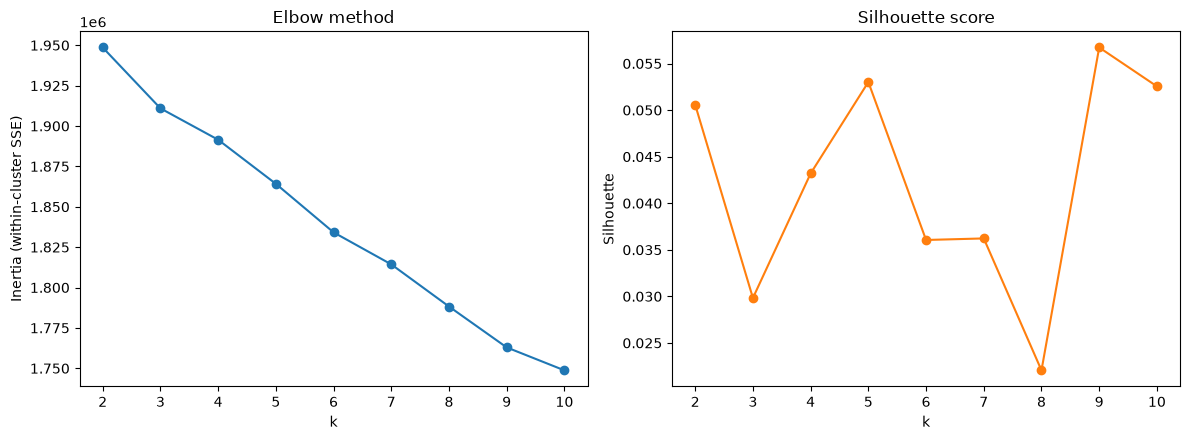

,k,Inertia,Silhouette
0,2,1.948618e+06,0.0506
1,3,1.910943e+06,0.0298
2,4,1.891510e+06,0.0432
3,5,1.864219e+06,0.0530
4,6,1.834172e+06,0.0361
5,7,1.814345e+06,0.0362
6,8,1.788254e+06,0.0221
7,9,1.762939e+06,0.0567
8,10,1.748735e+06,0.0526


In [4]:
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test, Xs_val = (scaler.transform(d) for d in (X_train, X_test, X_val))

k_range = range(2, 11)
inertias, silhouettes = [], []
for k in k_range:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs_train)
    inertias.append(km_k.inertia_)
    silhouettes.append(silhouette_score(Xs_train, km_k.labels_, sample_size=5000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(k_range, inertias, marker="o")
axes[0].set(title="Elbow method", xlabel="k", ylabel="Inertia (within-cluster SSE)")
axes[1].plot(k_range, silhouettes, marker="o", color="tab:orange")
axes[1].set(title="Silhouette score", xlabel="k", ylabel="Silhouette")
plt.tight_layout()
plt.show()

pd.DataFrame({"k": list(k_range), "Inertia": inertias, "Silhouette": silhouettes}).round(4)

The next cell prints the numbers behind the plots.

In [5]:
best_k = list(k_range)[int(np.argmax(silhouettes))]
print(f"Best silhouette: k={best_k} ({max(silhouettes):.4f})")
print(f"Silhouette at k=2: {silhouettes[0]:.4f}")
drops = -np.diff(inertias) / np.array(inertias[:-1])
print("Inertia drop from k to k+1 (%):", {k: round(d * 100, 1) for k, d in zip(list(k_range)[:-1], drops)})

Best silhouette: k=9 (0.0567)
Silhouette at k=2: 0.0506
Inertia drop from k to k+1 (%): {2: np.float64(1.9), 3: np.float64(1.0), 4: np.float64(1.4), 5: np.float64(1.6), 6: np.float64(1.1), 7: np.float64(1.4), 8: np.float64(1.4), 9: np.float64(0.8)}


Income has two classes, so **k = 2** is used below to compare with the classifiers. The elbow and silhouette values above show how well the data supports that choice.

## 5. K-means with k = 2

Each cluster gets the majority income label of the **training** rows in it. Then the test rows are scored with that mapping.

In [6]:
km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xs_train)
train_clusters = km.labels_
mapping = {c: int(y_train[train_clusters == c].mean() >= 0.5) for c in range(2)}
print("Cluster -> income label:", mapping)

pd.crosstab(pd.Series(train_clusters, name="Cluster"), y_train.reset_index(drop=True).rename("Actual income"))

Cluster -> income label: {0: 0, 1: 0}


Actual income,0,1
Cluster,,
0,10198,644
1,5686,4569


In [7]:
test_clusters = km.predict(Xs_test)
km_pred = pd.Series(test_clusters).map(mapping).to_numpy()

print(f"Test accuracy: {accuracy_score(y_test, km_pred):.4f}")
print(f"Majority class baseline (test): {max(y_test.mean(), 1 - y_test.mean()):.4f}")
print(f"Silhouette (test, sample_size=5000): {silhouette_score(Xs_test, test_clusters, sample_size=5000, random_state=42):.4f}")
print(f"Adjusted Rand Index (test): {adjusted_rand_score(y_test, test_clusters):.4f}")
print(f"Normalized Mutual Info (test): {normalized_mutual_info_score(y_test, test_clusters):.4f}")
print()
print(classification_report(y_test, km_pred, target_names=["<=50K", ">50K"], zero_division=0))

Test accuracy: 0.7414
Majority class baseline (test): 0.7414


Silhouette (test, sample_size=5000): 0.0512
Adjusted Rand Index (test): 0.1836
Normalized Mutual Info (test): 0.1933

              precision    recall  f1-score   support

       <=50K       0.74      1.00      0.85      3352
        >50K       0.00      0.00      0.00      1169

    accuracy                           0.74      4521
   macro avg       0.37      0.50      0.43      4521
weighted avg       0.55      0.74      0.63      4521



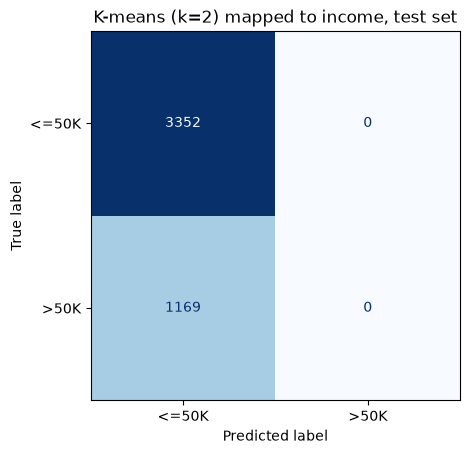

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_test, km_pred, display_labels=["<=50K", ">50K"], cmap="Blues", colorbar=False)
plt.title("K-means (k=2) mapped to income, test set")
plt.show()

## 6. Visualizing the clusters (PCA to 2D)

The plot uses a fixed random sample of 3000 training rows so the points stay readable.

Variance explained by PC1 and PC2: [0.0372, 0.0286]
Total: 0.0658


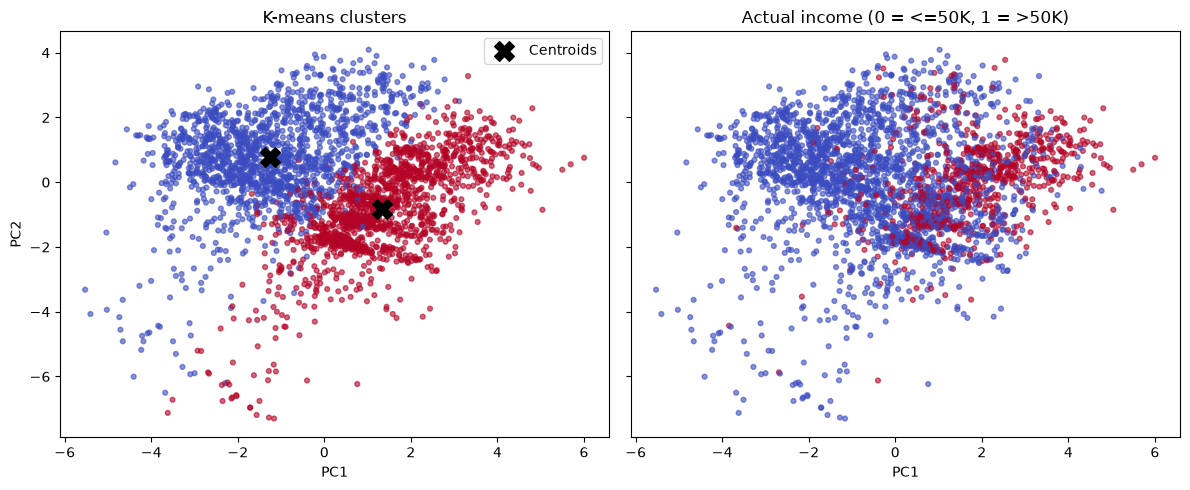

In [9]:
pca = PCA(n_components=2, random_state=42).fit(Xs_train)
print("Variance explained by PC1 and PC2:", pca.explained_variance_ratio_.round(4).tolist())
print("Total:", round(pca.explained_variance_ratio_.sum(), 4))

idx = np.random.RandomState(42).choice(len(Xs_train), 3000, replace=False)
P = pca.transform(Xs_train[idx])
centers_2d = pca.transform(km.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
axes[0].scatter(P[:, 0], P[:, 1], c=train_clusters[idx], cmap="coolwarm", s=12, alpha=0.6)
axes[0].scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X", s=200, label="Centroids")
axes[0].set(title="K-means clusters", xlabel="PC1", ylabel="PC2")
axes[0].legend()
axes[1].scatter(P[:, 0], P[:, 1], c=y_train.to_numpy()[idx], cmap="coolwarm", s=12, alpha=0.6)
axes[1].set(title="Actual income (0 = <=50K, 1 = >50K)", xlabel="PC1")
plt.tight_layout()
plt.show()

Two principal components keep only part of the variance, so this is an approximate view. It shows how closely the clusters line up with the real income classes.

## 7. Cluster profiles

In [10]:
num_cols = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
dummy_cols = [c for c in ["sex_Male", "marital-status_Married-civ-spouse", "relationship_Husband",
                          "relationship_Own-child", "marital-status_Never-married"] if c in X_train.columns]
profile = X_train[num_cols + dummy_cols].copy()
profile["cluster"] = train_clusters
profile[">50K share"] = y_train.values
profile.groupby("cluster").mean().T.round(3)

cluster,0,1
age,34.296,42.976
education-num,9.841,10.394
capital-gain,368.739,1781.308
capital-loss,51.883,126.801
hours-per-week,37.982,44.083
sex_Male,0.466,0.897
marital-status_Married-civ-spouse,0.004,0.959
relationship_Own-child,0.280,0.006
marital-status_Never-married,0.616,0.001
>50K share,0.059,0.446


## 8. Comparison with previous results

The previous models are re-run on the exact same split with the exact same settings as Week 09. No cross-validation is used (SVM on Adult is too slow). K-means is scored with its cluster-to-income mapping.

In [11]:
models = {
    "Decision Tree (Gini)": DecisionTreeClassifier(criterion="gini", random_state=42),
    "Decision Tree (Entropy)": DecisionTreeClassifier(criterion="entropy", random_state=42),
    "Decision Tree (Entropy, max_depth=8)": DecisionTreeClassifier(criterion="entropy", max_depth=8, random_state=42),
    "SVM (RBF kernel)": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
preds = {name: m.fit(X_train, y_train).predict(X_test) for name, m in models.items()}
preds["K-means (k=2)"] = km_pred

comparison = pd.DataFrame([{
    "Model": name,
    "Accuracy": accuracy_score(y_test, p),
    "Precision": precision_score(y_test, p, zero_division=0),
    "Recall": recall_score(y_test, p, zero_division=0),
    "F1": f1_score(y_test, p, zero_division=0),
} for name, p in preds.items()]).sort_values("Accuracy", ascending=False).reset_index(drop=True)
comparison.index += 1
comparison.round(4)

,Model,Accuracy,Precision,Recall,F1
1,"Decision Tree (Entropy, max_depth=8)",0.8456,0.8000,0.5372,0.6428
2,SVM (RBF kernel),0.8370,0.7748,0.5210,0.6230
3,KNN (k=5),0.8153,0.6667,0.5714,0.6154
4,Decision Tree (Entropy),0.8142,0.6442,0.6287,0.6364
5,Decision Tree (Gini),0.8120,0.6393,0.6262,0.6327
6,K-means (k=2),0.7414,0.0000,0.0000,0.0000


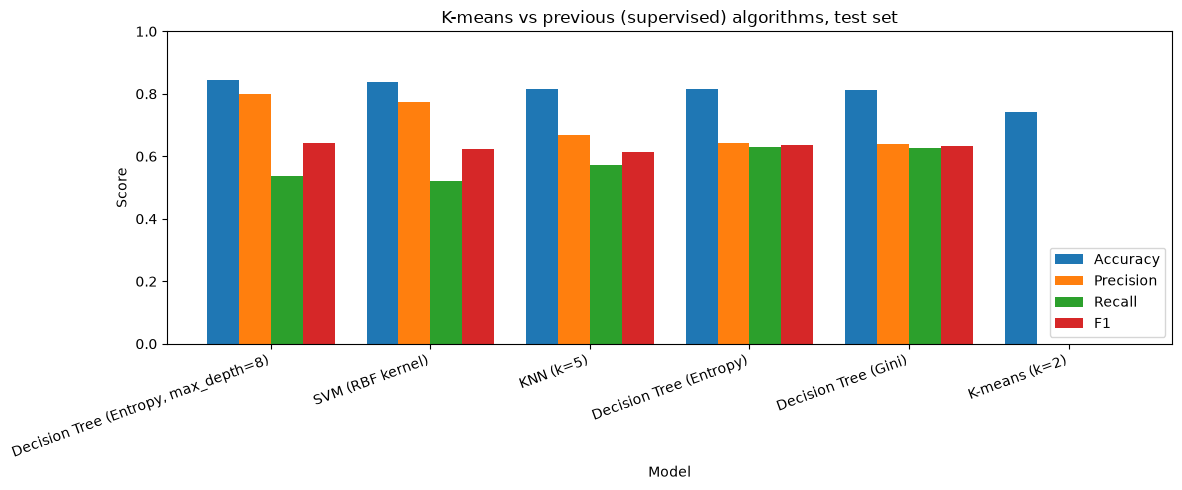

In [12]:
metrics = ["Accuracy", "Precision", "Recall", "F1"]
ax = comparison.set_index("Model")[metrics].plot.bar(figsize=(12, 5), width=0.8)
ax.set(title="K-means vs previous (supervised) algorithms, test set", ylabel="Score", ylim=(0, 1))
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. Discussion

The next cell prints the numbers used in the conclusions.

In [13]:
km_row = comparison[comparison["Model"] == "K-means (k=2)"].iloc[0]
best = comparison.iloc[0]
print(f"K-means: accuracy {km_row['Accuracy']:.4f}, precision {km_row['Precision']:.4f}, recall {km_row['Recall']:.4f}, F1 {km_row['F1']:.4f}")
print(f"Best model: {best['Model']}, accuracy {best['Accuracy']:.4f}, F1 {best['F1']:.4f}")
print(f"Accuracy gap: {(best['Accuracy'] - km_row['Accuracy']) * 100:.2f} points")

K-means: accuracy 0.7414, precision 0.0000, recall 0.0000, F1 0.0000
Best model: Decision Tree (Entropy, max_depth=8), accuracy 0.8456, F1 0.6428
Accuracy gap: 10.42 points


**Conclusions**

- **K-means is last.** At k = 2 it scores 0.7414 accuracy on the test set. The best model (Decision Tree, entropy, max_depth=8) scores 0.8456, a gap of 10.42 points.
- **It predicts "<=50K" for everyone.** Both clusters map to label 0, because even the richer cluster (cluster 1) has only 44.6% of rows above 50K (cluster 0 has 5.9%). So accuracy equals the majority-class baseline (0.7414), and precision, recall and F1 for ">50K" are all 0.
- **The clusters follow other structure, not income.** The profiles show the split is mostly about marital status and family role (cluster 1: 95.9% married-civ-spouse, 89.7% male; cluster 0: 61.6% never married). Income is only partly linked to that. The Adjusted Rand Index (0.1836) and Normalized Mutual Info (0.1933) are low.
- **The data has no clear clusters.** Silhouette is near 0 for every k (0.0506 at k = 2, best 0.0567 at k = 9), the elbow is gradual, and two PCA components keep only 6.58% of the variance. So the 96 scaled features do not form compact, separate groups.
- **This is not a like-for-like comparison.** The supervised models learned from the income labels. K-means never saw them. The result shows that income is not the main natural grouping in this data, not that k-means is a bad algorithm. When labels exist, a supervised model is the better choice for predicting income. K-means is still useful to explore and profile the people.